# 01 · Caracterização da base de dados

Material para a **seção 4.1 do relatório** (caracterização e justificativa da base) e para a parte de divisão de dados da seção 4.2.

Este notebook usa a base inteira **somente para descrevê-la**. Nenhuma decisão de modelagem é tomada aqui. A divisão treino/teste é gerada por `scripts/make_split.py` e apenas conferida no final.

In [1]:
# Torna o pacote `tde2` (em ../src) importável, rodando local ou no Colab após `git clone`.
import sys
from pathlib import Path

_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "tde2").is_dir())
sys.path.insert(0, str(_root / "src"))

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tde2 import config as C
from tde2.data import load_raw, verify_split

C.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

# Paleta: azul = Normal (0), laranja = Doença cardíaca (1)
COLORS = {0: "#2a78d6", 1: "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "font.size": 10,
})

## 1. Origem

**Heart Failure Prediction Dataset**, publicado no Kaggle por *fedesoriano* (set. 2021): https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction

A base junta cinco bases de doença cardíaca do **UCI Machine Learning Repository** (Cleveland 303, Hungarian 294, Switzerland 123, Long Beach VA 200 e Statlog Heart 270, somando 1190 registros). O autor removeu 272 duplicatas, chegando a **918 pacientes**.

> fedesoriano. *Heart Failure Prediction Dataset*. Kaggle, 2021. Disponível em: https://www.kaggle.com/fedesoriano/heart-failure-prediction.
>
> Fonte original: JANOSI, A.; STEINBRUNN, W.; PFISTERER, M.; DETRANO, R. *Heart Disease*. UCI Machine Learning Repository, 1988. https://doi.org/10.24432/C52P4X.

In [3]:
df = load_raw()
print(f"{df.shape[0]} exemplos, {len(C.FEATURES)} atributos preditivos, alvo = {C.TARGET}")
df.head()

918 exemplos, 11 atributos preditivos, alvo = HeartDisease


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
row_id,,,,,,,,,,,,
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 2. Dicionário de atributos

| Atributo | Tipo | Descrição | Valores |
|---|---|---|---|
| Age | numérico | idade do paciente | anos |
| Sex | categórico (binário) | sexo | M, F |
| ChestPainType | categórico | tipo de dor torácica | TA (angina típica), ATA (angina atípica), NAP (dor não anginosa), ASY (assintomático) |
| RestingBP | numérico | pressão arterial em repouso | mm Hg |
| Cholesterol | numérico | colesterol sérico | mg/dl |
| FastingBS | binário | glicemia em jejum > 120 mg/dl | 1 = sim, 0 = não |
| RestingECG | categórico | eletrocardiograma em repouso | Normal, ST (anormalidade ST-T), LVH (hipertrofia ventricular esquerda) |
| MaxHR | numérico | frequência cardíaca máxima atingida | 60 a 202 bpm |
| ExerciseAngina | categórico (binário) | angina induzida por exercício | Y, N |
| Oldpeak | numérico | depressão do segmento ST (*oldpeak*) | contínuo; negativo = elevação do ST |
| ST_Slope | categórico | inclinação do segmento ST no pico do exercício | Up, Flat, Down |
| **HeartDisease** | **alvo** | **presença de doença cardíaca** | **1 = doença, 0 = normal** |

In [4]:
summary = pd.DataFrame({
    "tipo": ["numérico"] * len(C.NUMERIC) + ["binário"] * len(C.BINARY) + ["categórico"] * len(C.CATEGORICAL),
}, index=C.FEATURES)
summary["dtype"] = df[C.FEATURES].dtypes.astype(str)
summary["n_valores_distintos"] = df[C.FEATURES].nunique()
summary["NaN"] = df[C.FEATURES].isna().sum()
summary

,tipo,dtype,n_valores_distintos,NaN
Age,numérico,int64,50,0
RestingBP,numérico,int64,67,0
Cholesterol,numérico,int64,222,0
MaxHR,numérico,int64,119,0
Oldpeak,numérico,float64,53,0
FastingBS,binário,int64,2,0
Sex,categórico,str,2,0
ChestPainType,categórico,str,4,0
RestingECG,categórico,str,3,0
ExerciseAngina,categórico,str,2,0


In [5]:
df[C.NUMERIC].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.511,9.433,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.397,18.514,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.800,109.384,0.0,173.25,223.0,267.0,603.0
MaxHR,918.0,136.809,25.460,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887,1.067,-2.6,0.00,0.6,1.5,6.2


In [6]:
for col in C.CATEGORICAL:
    print(col, df[col].value_counts().to_dict())

Sex {'M': 725, 'F': 193}
ChestPainType {'ASY': 496, 'NAP': 203, 'ATA': 173, 'TA': 46}
RestingECG {'Normal': 552, 'LVH': 188, 'ST': 178}
ExerciseAngina {'N': 547, 'Y': 371}
ST_Slope {'Flat': 460, 'Up': 395, 'Down': 63}


## 3. Distribuição das classes

In [7]:
counts = df[C.TARGET].value_counts().sort_index()
class_table = pd.DataFrame({
    "classe": [C.CLASS_NAMES[k] for k in counts.index],
    "n": counts.values,
    "proporção": (counts / counts.sum()).round(4).values,
}, index=counts.index)
class_table

,classe,n,proporção
HeartDisease,,,
0,Normal,410,0.447
1,Doença cardíaca,508,0.553


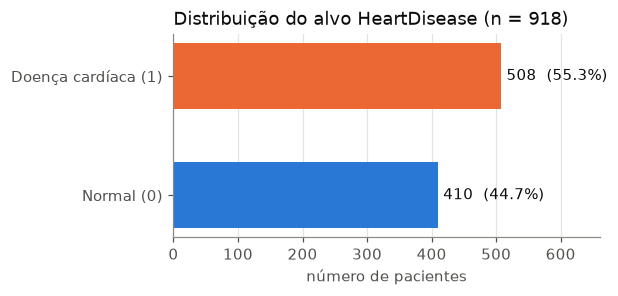

In [8]:
fig, ax = plt.subplots(figsize=(5, 2.4))
labels = [f"{C.CLASS_NAMES[k]} ({k})" for k in counts.index]
bars = ax.barh(labels, counts.values, color=[COLORS[k] for k in counts.index], height=0.55)
for b, n in zip(bars, counts.values):
    ax.text(b.get_width() + 8, b.get_y() + b.get_height() / 2,
            f"{n}  ({n / counts.sum():.1%})", va="center", color="#0b0b0b")
ax.set_xlabel("número de pacientes")
ax.set_xlim(0, counts.max() * 1.3)
ax.grid(axis="y", visible=False)
ax.set_title("Distribuição do alvo HeartDisease (n = 918)", loc="left", color="#0b0b0b")
fig.savefig(C.FIGURES_DIR / "01_distribuicao_classes.png")
plt.show()

A base é **levemente desbalanceada** (55,3% positivos contra 44,7% negativos). Um classificador que sempre responde "doença" acerta 55,3%, mas tem recall nulo para a classe normal. Por isso a acurácia sozinha não basta, e a divisão e a validação cruzada são **estratificadas**.

## 4. Qualidade dos dados

Não há `NaN` nem linhas duplicadas, mas há **valores zero fisiologicamente impossíveis**, que são ausentes disfarçados.

In [9]:
print("NaN no total:", int(df.isna().sum().sum()))
print("Linhas duplicadas:", int(df.duplicated().sum()))
quality = pd.DataFrame({
    "zeros": (df[C.NUMERIC] == 0).sum(),
    "negativos": (df[C.NUMERIC] < 0).sum(),
    "mínimo": df[C.NUMERIC].min(),
    "máximo": df[C.NUMERIC].max(),
})
quality

NaN no total: 0
Linhas duplicadas: 0


,zeros,negativos,mínimo,máximo
Age,0,0,28.0,77.0
RestingBP,1,0,0.0,200.0
Cholesterol,172,0,0.0,603.0
MaxHR,0,0,60.0,202.0
Oldpeak,368,13,-2.6,6.2


In [10]:
chol_zero = (df["Cholesterol"] == 0).map({True: "Cholesterol = 0", False: "Cholesterol > 0"})
pd.crosstab(chol_zero, df[C.TARGET].map(C.CLASS_NAMES), margins=True, normalize=False).assign(
    **{"% doença": lambda t: (t["Doença cardíaca"] / t["All"] * 100).round(1)}
)

HeartDisease,Doença cardíaca,Normal,All,% doença
Cholesterol,,,,
Cholesterol = 0,152,20,172,88.4
Cholesterol > 0,356,390,746,47.7
All,508,410,918,55.3


Leitura dos zeros:

- **Cholesterol = 0 em 172 linhas (18,7%).** Colesterol sérico zero não existe. Esses registros vêm quase todos da base Switzerland, que não media colesterol. Como **88% deles são positivos** (contra 48% no resto), a ausência carrega informação. No pipeline, o zero vira ausente, é imputado pela mediana do treino de cada dobra e ganha uma coluna indicadora `missingindicator_Cholesterol`.
- **RestingBP = 0 em 1 linha.** Mesmo tratamento (imputação pela mediana).
- **Oldpeak negativo (13 linhas)** é clinicamente válido (elevação do segmento ST) e fica como está.

Toda imputação acontece **dentro do pipeline** (`tde2.preprocessing.build_preprocessor`), nunca sobre a base inteira.

## 5. Atributos por classe

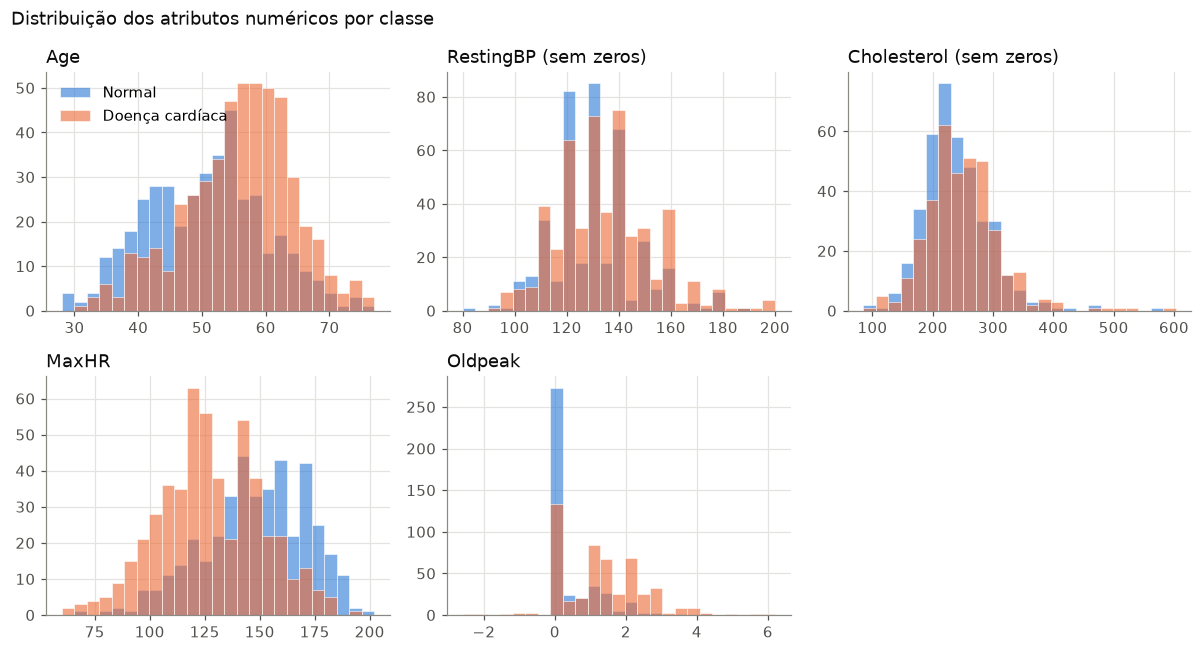

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, col in zip(axes.flat, C.NUMERIC):
    data = df[[col, C.TARGET]]
    if col in C.ZERO_AS_MISSING:
        data = data[data[col] != 0]  # zeros (ausentes) fora do histograma
    bins = np.histogram_bin_edges(data[col], bins=25)
    for k in (0, 1):
        ax.hist(data.loc[data[C.TARGET] == k, col], bins=bins, alpha=0.6,
                color=COLORS[k], label=C.CLASS_NAMES[k], edgecolor="white", linewidth=0.6)
    ax.set_title(col + (" (sem zeros)" if col in C.ZERO_AS_MISSING else ""), loc="left", color="#0b0b0b")
axes.flat[0].legend(frameon=False)
axes.flat[-1].axis("off")
fig.suptitle("Distribuição dos atributos numéricos por classe", x=0.01, ha="left", color="#0b0b0b")
fig.tight_layout()
fig.savefig(C.FIGURES_DIR / "01_numericos_por_classe.png")
plt.show()

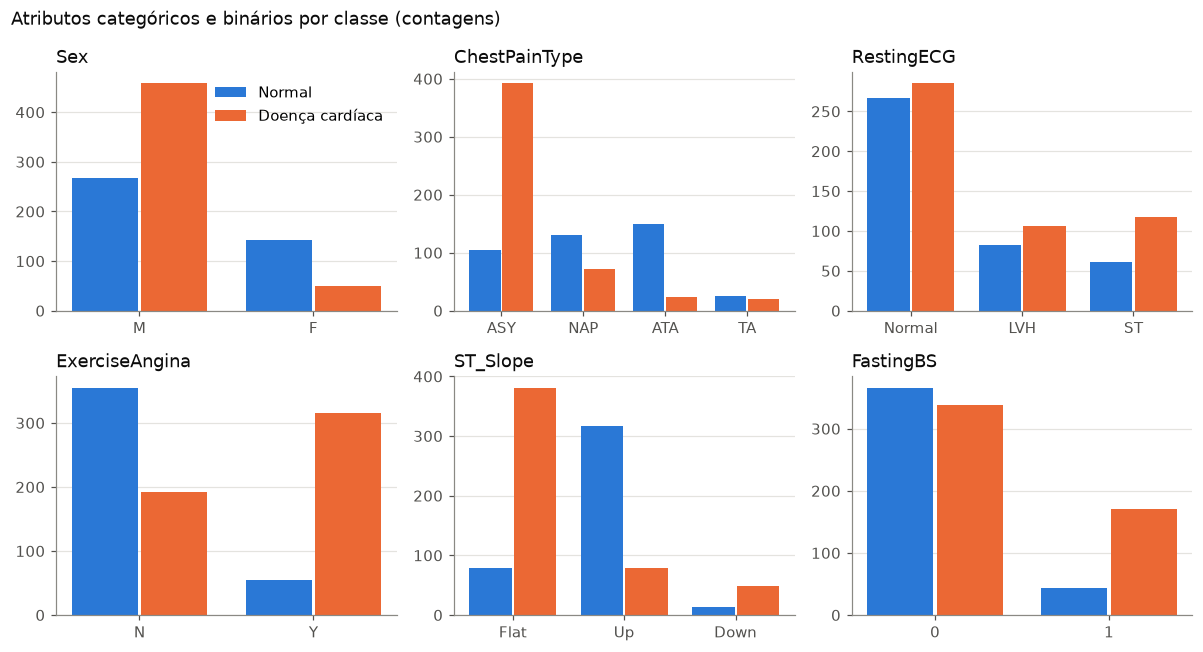

In [12]:
cat_cols = C.CATEGORICAL + C.BINARY
fig, axes = plt.subplots(2, 3, figsize=(11, 6))
for ax, col in zip(axes.flat, cat_cols):
    ct = pd.crosstab(df[col], df[C.TARGET])
    order = ct.sum(axis=1).sort_values(ascending=False).index
    ct = ct.loc[order]
    x = np.arange(len(ct))
    w = 0.38
    for i, k in enumerate((0, 1)):
        ax.bar(x + (i - 0.5) * (w + 0.02), ct[k], width=w, color=COLORS[k], label=C.CLASS_NAMES[k])
    ax.set_xticks(x, ct.index.astype(str))
    ax.grid(axis="x", visible=False)
    ax.set_title(col, loc="left", color="#0b0b0b")
axes.flat[0].legend(frameon=False)
fig.suptitle("Atributos categóricos e binários por classe (contagens)", x=0.01, ha="left", color="#0b0b0b")
fig.tight_layout()
fig.savefig(C.FIGURES_DIR / "01_categoricos_por_classe.png")
plt.show()

In [13]:
# Taxa de doença por categoria: dá a força individual de cada atributo categórico
rates = []
for col in cat_cols:
    g = df.groupby(col)[C.TARGET].agg(n="size", taxa_doenca="mean")
    g.index = pd.MultiIndex.from_product([[col], g.index.astype(str)], names=["atributo", "valor"])
    rates.append(g)
pd.concat(rates).round(3)

n  taxa_doenca
atributo       valor                   
Sex            F       193        0.259
               M       725        0.632
ChestPainType  ASY     496        0.790
               ATA     173        0.139
               NAP     203        0.355
               TA       46        0.435
RestingECG     LVH     188        0.564
               Normal  552        0.516
               ST      178        0.657
ExerciseAngina N       547        0.351
               Y       371        0.852
ST_Slope       Down     63        0.778
               Flat    460        0.828
               Up      395        0.197
FastingBS      0       704        0.480
               1       214        0.794

## 6. Divisão treino/teste (gerada por `scripts/make_split.py`)

- **2/3 treino (612) / 1/3 teste (306)**, estratificada pelo alvo, `random_state = 42`.
- O teste fica guardado e é usado **uma única vez**, ao final, depois que todas as configurações estiverem escolhidas.
- Toda seleção e ajuste usa **validação cruzada estratificada de 10 dobras sobre o treino** (`tde2.data.get_cv()`), com as mesmas dobras para todas as alternativas.
- Os hashes SHA-256 dos arquivos ficam em `dataset/splits/split_report.json`, o que permite a terceiros conferir que usam exatamente a mesma divisão.

In [14]:
verify_split()  # levanta erro se os arquivos não baterem com a base bruta / hashes
report = json.loads(C.SPLIT_REPORT.read_text())
split_table = pd.DataFrame({
    part: {
        "n": sum(v["n"] for v in report["class_distribution"][part].values()),
        "Normal (0)": report["class_distribution"][part]["0"]["n"],
        "Doença (1)": report["class_distribution"][part]["1"]["n"],
        "% Doença": round(report["class_distribution"][part]["1"]["prop"] * 100, 1),
    }
    for part in ("total", "train", "test")
}).T
split_table

,n,Normal (0),Doença (1),% Doença
total,918.0,410.0,508.0,55.3
train,612.0,273.0,339.0,55.4
test,306.0,137.0,169.0,55.2


In [15]:
pd.DataFrame(report["zeros_as_missing"]).T.rename_axis("zeros por partição")

,train,test
zeros por partição,,
RestingBP,0,1
Cholesterol,109,63


In [16]:
print("Semente:", report["seed"])
print("Versões:", report["versions"])

Semente: 42
Versões: {'python': '3.12.3', 'numpy': '2.5.5', 'pandas': '3.1.1', 'scikit-learn': '1.9.1'}


**Observação:** a estratificação é feita só pelo alvo. Por acaso, os zeros de colesterol ficaram um pouco mais concentrados no teste (63/306 = 20,6%) que no treino (109/612 = 17,8%), e o único `RestingBP = 0` caiu no teste. O pipeline lida com isso (a mediana é aprendida no treino), mas o fato deve constar no relatório como característica da partição.